# Población nacida en el extranjero

In [ ]:
# Parámetros de la gráfica
SLUG = "seguridad-social"  # carpeta en research/temas/
GRAFICA_ID = "poblacion-nacida-extranjero"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Población nacida en el extranjero"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% de la población"
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** Qué porcentaje de las personas que viven en el país ha nacido en otro país.

**Cómo se lee.** Un valor de 18 significa que 18 de cada 100 residentes nacieron en el extranjero.

**Limitaciones.**
- **País de nacimiento, no nacionalidad.** Incluye a las personas nacidas fuera que tienen la nacionalidad del país: en España, muchas nacidas en Hispanoamérica y en otros países de la UE, y también hijos de españoles nacidos en el extranjero. Por eso es más alto que el porcentaje de extranjeros, que usa `extranjeros-cotizantes-perceptores`.
- No distingue la situación administrativa: cuenta a quienes están empadronados o censados, tengan o no permiso de residencia.
- **Fuentes distintas por país.** España y la UE-27 salen de Eurostat (población a 1 de enero, del padrón y los registros de población). EE. UU. y Canadá salen de la base de migración internacional de la OCDE, que recoge las encuestas y censos de cada país: en Canadá solo hay dato los años de censo, cada cinco años. La OCDE no publica una media de sus miembros.

## 2. Descarga

- **España y UE-27:** Eurostat, población a 1 de enero por país de nacimiento (`migr_pop3ctb`), todas las edades y ambos sexos: nacida en el extranjero (`FOR`) y total (`TOTAL`).
- **EE. UU. y Canadá:** OCDE, base de migración internacional (`OECD.ELS.IMD,DSD_MIG_F@DF_MIG_POPF,1.0`), población nacida en el extranjero (`B14`, todos los países de nacimiento, `W`, personas), dividida entre la población total de la OCDE (`OECD.ELS.SAE,DSD_POPULATION@DF_POP_HIST,1.0`, `POP`). También España, para compararla con Eurostat.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from lib import eurostat, oecd
from lib.tipos import FuenteMeta

BASE = {"freq": "A", "age": "TOTAL", "sex": "T", "unit": "NR"}
nacidos_fuera, fuentes_eu = eurostat.get("migr_pop3ctb", {**BASE, "c_birth": "FOR"}, desde=DESDE)
total, _ = eurostat.get("migr_pop3ctb", {**BASE, "c_birth": "TOTAL"}, desde=DESDE)

# DSD_MIG_F: REF_AREA.BIRTH_COUNTRY.FREQ.MEASURE.SEX.BIRTH_PLACE.EDUCATION_LEV.UNIT_MEASURE
DATAFLOW_MIG = "OECD.ELS.IMD,DSD_MIG_F@DF_MIG_POPF,1.0"
# DSD_POPULATION: REF_AREA.MEASURE.UNIT_MEASURE.SEX.AGE.TIME_HORIZ
DATAFLOW_POB = "OECD.ELS.SAE,DSD_POPULATION@DF_POP_HIST,1.0"
AREAS = {"USA": "eeuu", "CAN": "canada", "ESP": "espana_ocde", "OECD": "ocde"}
b14, _ = oecd.get(DATAFLOW_MIG, "{AREA}.W.A.B14._T._Z._Z.PS", areas=AREAS, desde=DESDE)
pob, _ = oecd.get(DATAFLOW_POB, "{AREA}.POP.PS._T._T.", areas={k: v for k, v in AREAS.items() if k != "OECD"}, desde=DESDE)
print("Áreas con población nacida en el extranjero en la OCDE:", sorted(b14["serie"].unique()))

Áreas con población nacida en el extranjero en la OCDE: ['canada', 'eeuu', 'espana_ocde']


## 3. Transformación

- **España y UE-27:** población nacida en el extranjero entre la población total, por 100 (Eurostat).
- **EE. UU. y Canadá:** población nacida en el extranjero de la OCDE entre la población total de la OCDE, por 100.
- **OCDE:** `null`.
- Comprobación: España en las dos fuentes. No se enlazan con los años anteriores a 2002, que solo da la OCDE, porque en 2002-2007 las dos fuentes no coinciden.

In [ ]:
serie = lambda d, s: d[d["serie"] == s].set_index("periodo")["valor"]
filas = []
for g in ("espana", "ue27"):
    pct = (serie(nacidos_fuera, g) / serie(total, g) * 100).dropna()
    filas.append(pd.DataFrame({"serie": g, "periodo": pct.index, "valor": pct.values}))
pct_ocde = {}
for g in ("eeuu", "canada", "espana_ocde"):
    pct_ocde[g] = (serie(b14, g) / serie(pob, g) * 100).dropna()
    if g != "espana_ocde":
        filas.append(pd.DataFrame({"serie": g, "periodo": pct_ocde[g].index, "valor": pct_ocde[g].values}))
assert "ocde" not in set(b14["serie"]), "la OCDE publica ya su media: usarla"
filas.append(pd.DataFrame({"serie": ["ocde"], "periodo": [DESDE], "valor": [float("nan")]}))
df = pd.concat(filas, ignore_index=True)
assert df["valor"].dropna().between(0, 60).all(), "porcentaje fuera de rango"

HOY = fuentes_eu[0].fecha_consulta
fuentes = [
    FuenteMeta(g, eurostat.ORGANISMO, "migr_pop3ctb (c_birth=FOR entre c_birth=TOTAL, age=TOTAL, sex=T)",
               fuentes_eu[0].url, HOY) for g in ("espana", "ue27")
] + [
    FuenteMeta(g, oecd.ORGANISMO, "DSD_MIG_F@DF_MIG_POPF (B14, W) entre DSD_POPULATION@DF_POP_HIST (POP)",
               oecd.URL_EXPLORER, HOY) for g in ("eeuu", "canada")
] + [FuenteMeta("ocde", oecd.ORGANISMO, "DSD_MIG_F@DF_MIG_POPF: sin media de la OCDE", oecd.URL_EXPLORER, HOY)]

comp = pd.DataFrame({"Eurostat": filas[0].set_index("periodo")["valor"], "OCDE": pct_ocde["espana_ocde"]})
comp["OCDE − Eurostat"] = comp["OCDE"] - comp["Eurostat"]
display(comp.round(2))
dif = comp["OCDE − Eurostat"].dropna()
DESDE_IGUAL = int(dif[dif.abs() >= 0.1].index.max()) + 1
DIF_ANTES = dif.loc[: DESDE_IGUAL - 1].abs().max()
DIF_DESPUES = dif.loc[DESDE_IGUAL:].abs().max()
PRIMERO_OCDE_ES = int(pct_ocde["espana_ocde"].index.min())
ANIOS_CAN = sorted(pct_ocde["canada"].index)

,Eurostat,OCDE,OCDE − Eurostat
periodo,,,
1998,NaN,2.92,NaN
1999,NaN,3.12,NaN
2000,NaN,3.63,NaN
2001,NaN,4.83,NaN
2002,5.69,6.26,0.57
2003,7.13,7.83,0.69
2004,8.34,8.62,0.28
2005,9.49,10.06,0.57
2006,10.54,10.91,0.37


### Notas

In [ ]:
def fmt(x, decimales=1):
    return estilos.formato_es(x, decimales).replace("-", "−")


def unir(xs):
    xs = [str(x) for x in xs]
    return xs[0] if len(xs) == 1 else f"{', '.join(xs[:-1])} y {xs[-1]}"


NOTAS = [
    "España y UE-27: Eurostat, población a 1 de enero por país de nacimiento (migr_pop3ctb): nacida en el extranjero "
    "entre la población total. Media UE-27 de composición actual (EU27_2020).",
    "EE. UU. y Canadá: OCDE, base de migración internacional (DSD_MIG_F@DF_MIG_POPF, B14), población nacida en el "
    "extranjero según las encuestas y censos de cada país, entre la población total de la OCDE (DSD_POPULATION). "
    f"Canadá solo tiene dato los años de censo ({unir(ANIOS_CAN)}).",
    "OCDE: sin dato. La base de migración internacional no publica la media de la OCDE.",
    f"España en las dos fuentes: la OCDE da España desde {PRIMERO_OCDE_ES}; desde "
    f"{DESDE_IGUAL} su porcentaje coincide con el de Eurostat (diferencia máxima de {fmt(DIF_DESPUES, 2)} puntos), pero "
    f"antes llega a ser {fmt(DIF_ANTES)} puntos más alto, así que no se enlaza para los años anteriores a 2002.",
    "Cuenta el país de nacimiento y no la nacionalidad: incluye a las personas nacidas fuera que tienen la "
    "nacionalidad del país y no distingue la situación administrativa.",
]
for n in NOTAS:
    print("-", n)

- España y UE-27: Eurostat, población a 1 de enero por país de nacimiento (migr_pop3ctb): nacida en el extranjero entre la población total. Media UE-27 de composición actual (EU27_2020).
- EE. UU. y Canadá: OCDE, base de migración internacional (DSD_MIG_F@DF_MIG_POPF, B14), población nacida en el extranjero según las encuestas y censos de cada país, entre la población total de la OCDE (DSD_POPULATION). Canadá solo tiene dato los años de censo (1996, 2001, 2006, 2011, 2016 y 2021).
- OCDE: sin dato. La base de migración internacional no publica la media de la OCDE.
- España en las dos fuentes: la OCDE da España desde 1998; desde 2007 su porcentaje coincide con el de Eurostat (diferencia máxima de 0,10 puntos), pero antes llega a ser 0,7 puntos más alto, así que no se enlaza para los años anteriores a 2002.
- Cuenta el país de nacimiento y no la nacionalidad: incluye a las personas nacidas fuera que tienen la nacionalidad del país y no distingue la situación administrativa.


## 4. Visualización

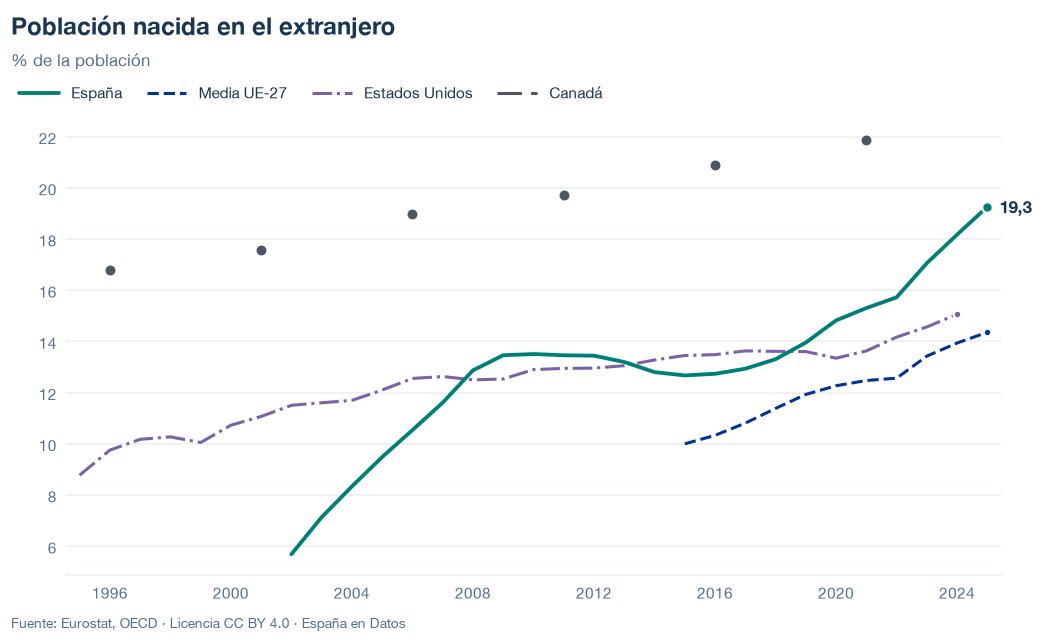

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/poblacion-nacida-extranjero.json y data/poblacion-nacida-extranjero.csv


## 6. Fuentes, notas y licencia

- Eurostat, `migr_pop3ctb` (`FOR` y `TOTAL`): España y UE-27.
- OCDE, base de migración internacional (`OECD.ELS.IMD,DSD_MIG_F@DF_MIG_POPF,1.0`, `B14`) y población (`OECD.ELS.SAE,DSD_POPULATION@DF_POP_HIST,1.0`, `POP`): EE. UU., Canadá y, para comparar, España.

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.